In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Generalization

The previous sections fitted a linear model with two weights and a bias to
1,000 synthetic examples and recovered its parameters almost exactly. There,
fitting the training data was the whole task, because we had generated the
data ourselves from a known model. In practice we fit a model to the examples
we have in order to predict the labels of examples we do not have yet, such as
the sale price of a house that comes on the market next month. Fitting the
data is not enough for that. Given 20 measurements at distinct inputs, a
polynomial of degree 19 passes through every one of them exactly, yet nothing
guarantees that it predicts a 21st measurement well. A model that reproduces
its training labels without capturing the pattern behind them has *memorized*
them, like a student who learns last year's exam answers by heart and then
faces new questions. What we want is *generalization*: good predictions on new
examples drawn from the same population as the training data.

Every model is fit to a finite sample, so the danger of memorization is
always present. Some medical studies can enroll only a few thousand patients,
and studies of rare diseases may have only hundreds. The largest public
collections of labeled photographs, such as ImageNet
[@Deng.Dong.Socher.ea.2009], contain millions of images. Even that is a
vanishing fraction of all possible megapixel images, so almost every input a
model meets after training is new.

This section asks how we can tell, from a finite sample, whether a model will
generalize. We first define the error on new data and estimate it with
examples held out from training. An experiment with polynomials then shows how
this error depends on the flexibility of the model and on the amount of data.
Finally, we use held-out data to choose among models without deceiving
ourselves.

## Training Error and Generalization Error

To say what "new examples from the same population" means, we need an
assumption that ties the training data to the data the model will see later.
The standard assumption is that all examples, those we train on and those we
later predict, are drawn *independently* from one *identical* distribution
$P(X, Y)$ over inputs and labels. This is the *IID assumption*. It often
fails in practice. A model trained on photographs taken in daylight may be
used at night, and a model trained on last year's purchases is applied to
this year's.
Without some assumption that relates the training distribution to the
distribution at deployment, data from the first says nothing about performance
on the second. Later chapters examine such shifts; here we assume IID data.

Under this assumption a model $f$ has two errors. Its *training error*, also
called the *empirical risk*, is the average loss over the $n$ training
examples,

$$R_\textrm{emp}[\mathbf{X}, \mathbf{y}, f] = \frac{1}{n} \sum_{i=1}^n l(\mathbf{x}^{(i)}, y^{(i)}, f(\mathbf{x}^{(i)})),$$

where $l(\mathbf{x}, y, f(\mathbf{x}))$ is the loss of predicting
$f(\mathbf{x})$ for an example with input $\mathbf{x}$ and label $y$, such as
the squared loss of that section. Its *generalization
error*, also called the *risk*, is the expected loss on a new example drawn
from $P$:

$$R[P, f] = \mathbb{E}_{(\mathbf{x}, y) \sim P} [l(\mathbf{x}, y, f(\mathbf{x}))] = \int \int l(\mathbf{x}, y, f(\mathbf{x})) \, p(\mathbf{x}, y) \;d\mathbf{x} \, dy.$$

The training error averages the loss over the sample we have. The
generalization error averages it over the whole population, which we would
see only by applying the model to an endless stream of new examples. Their
difference $R - R_\textrm{emp}$ is the *generalization gap*. We want a small
generalization error, and the gap tells us how far the training error, the
number we can compute, misleads us about it.

We cannot compute $R$, because we do not know $p(\mathbf{x}, y)$, but we can
estimate it. We set aside $n'$ examples, called a *test set*, that play no
part in training, and evaluate the formula for the training error on them
instead. Since these examples played no part in choosing the model, their
losses are $n'$ independent draws of a random variable whose mean is $R$.
Their average is therefore an unbiased estimate of $R$, and like any average
of $n'$ independent draws, it has the standard error $\sigma_l / \sqrt{n'}$,
where $\sigma_l$ is the standard deviation of the loss on one example. Four
times as many test examples halve the error of the estimate.

The training error has no such guarantee. The training examples were used to
choose the model, so their losses are not independent of it, and the model
looks better on them than it is. An extreme case shows how large the effect
can be. A model that stores the training set in a table and answers each
training input with its stored label has zero training error, yet it has
nothing to say about an input it has not seen. In general, the training error
is an optimistic estimate of $R$. When we trained the linear model of
that section, its loss on 1,000 held-out examples tracked its
training loss closely: a model with three parameters fit to 1,000 examples has
little room to memorize. The rest of this section asks when the gap is large,
and what to do about it.

## Underfitting and Overfitting

How large the gap is depends on how flexible the model is compared with the
amount of data. We can see this in an experiment in which we control both the
true function and the flexibility of the model.

### Polynomial Curve Fitting

Consider a single input $x$ and a real-valued label $y$. A polynomial of
degree $d$ predicts

$$\hat{y} = \sum_{j=0}^{d} w_j x^j = w_0 + w_1 x + w_2 x^2 + \cdots + w_d x^d.$$

This is linear regression with the powers $x, x^2, \ldots, x^d$ as features:
the weights are $w_1, \ldots, w_d$, and $w_0$ plays the role of the bias,
since it multiplies the constant feature $x^0 = 1$. The degree controls the
flexibility. A polynomial of higher degree contains every polynomial of lower
degree (set the extra weights to zero), so on the same training set the best
fit of a higher degree never has a larger training error. When the $n$
training inputs are distinct, degree $n - 1$ has as many weights as there are
examples and fits every label exactly (exercise
3).

We generate the data from a known cubic,

$$y = f^*(x) + \epsilon \quad \textrm{with} \quad f^*(x) = 5 + 1.2x - 3.4x^2 + 5.6x^3 \quad \textrm{and} \quad \epsilon \sim \mathcal{N}(0, \sigma^2),$$

where $\sigma = 0.1$ and the inputs $x$ are drawn uniformly from $[-1, 1]$.
The noise $\epsilon$ is the part of the label that no model can predict. We
draw only 20 training examples, so that high degrees have room to overfit,
and 1,000 test examples, enough to estimate the generalization error of the
models that fit well to within a few percent.

Because we generated the data, we know the error that no model can beat, the
noise variance $\sigma^2$. Real data do not reveal it, and the usual
reference there is the variance of the labels, $\textrm{Var}(y)$, which is
the mean squared error of predicting the mean label for every input. A model
is useful only if its mean squared error falls clearly below
$\textrm{Var}(y)$; one minus the ratio of the two, the fraction of the
variance that the model explains, is the *coefficient of determination*
$R^2$.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

The experiment needs no framework: NumPy draws the data and solves the
least-squares problems. `make_data` draws $n$ inputs and labels them with the noisy
cubic.

In [2]:
def target(x):
    """The cubic f* that generates the labels."""
    return 5 + 1.2 * x - 3.4 * x**2 + 5.6 * x**3

def make_data(rng, n, sigma):
    """Draw n inputs uniformly from [-1, 1] and label them by the noisy cubic."""
    x = rng.uniform(-1, 1, n)
    return x, target(x) + rng.normal(0, sigma, n)

sigma = 0.1                               # standard deviation of the noise
rng = np.random.default_rng()             # a new random draw on every run
x_train, y_train = make_data(rng, 20, sigma)  # few, so high degrees overfit
x_test, y_test = make_data(rng, 1000, sigma)

Fitting a polynomial of degree $d$ is least squares on the design matrix whose
columns are $1, x, \ldots, x^d$. As in that section, we let
the library routine `lstsq` compute the minimizer directly instead of running
gradient descent. We report the mean squared error, without the factor
$\frac{1}{2}$ of the training loss, so that a model that predicts $f^*$
exactly scores about $\sigma^2 = 0.01$ on new data.

In [3]:
def features(x, d):
    """Design matrix whose columns are the powers x^0, x^1, ..., x^d."""
    return x.reshape(-1, 1) ** np.arange(d + 1)

def fit_degree(x, y, d):
    """Least-squares weights of the degree-d polynomial fitted to (x, y)."""
    return np.linalg.lstsq(features(x, d), y, rcond=None)[0]

def mse(w, x, y):
    """Mean squared error of the polynomial with weights w on (x, y)."""
    return ((features(x, len(w) - 1) @ w - y) ** 2).mean()

How do fits of degree 1, 3, and 19 compare? We plot each one against the
training data and the true cubic.

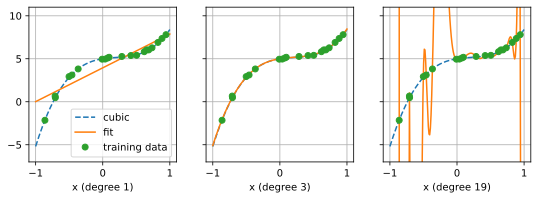

In [4]:
xs = np.linspace(-1, 1, 200)
_, axes = d2l.plt.subplots(1, 3, figsize=(9, 2.8), sharey=True)
for ax, d in zip(axes, (1, 3, 19)):
    w = fit_degree(x_train, y_train, d)
    d2l.plot([xs, xs, x_train], [target(xs), features(xs, d) @ w, y_train],
             xlabel=f'x (degree {d})', ylim=(-7, 11), fmts=('--', '-', 'o'),
             legend=['cubic', 'fit', 'training data'] if d == 1 else None,
             axes=ax)

The three panels show the two ways in which a model can fail. The straight
line (degree 1) cannot bend to follow the cubic, so it misses training points
and new points alike. This is *underfitting*. The cubic fit (degree 3) is hard
to tell apart from the truth. The polynomial of degree 19 passes through all
20 training points but swings far away from the cubic between them. This is
*overfitting*: the model fits the particular sample, noise included, at the
expense of the pattern. The training and test errors, and the largest weight
of each fit, quantify what the panels show.

In [5]:
for d in (1, 3, 19):
    w = fit_degree(x_train, y_train, d)
    print(f'degree {d:2d}: train {mse(w, x_train, y_train):.2g}, '
          f'test {mse(w, x_test, y_test):.2g}, '
          f'largest |weight| {np.abs(w).max():.2g}')

degree  1: train 0.83, test 2.1, largest |weight| 3.9
degree  3: train 0.0053, test 0.012, largest |weight| 5.5
degree 19: train 4.7e-18, test 9.2e+10, largest |weight| 7.5e+07


Every run draws new data, so the numbers change from run to run, but the
pattern does not. Degree 1 has errors far above the noise level on both
splits; its test error exceeds 1, more than a hundred times $\sigma^2 = 0.01$.
Degree 3 brings both errors down to the order of the noise level: it
predicts everything except the noise. Degree 19 has a training error far below the
noise level and a test error more than a thousand times larger than that of degree
3. The weights show why. The largest weight of the cubic fit is close to the
true coefficient 5.6. The fit of degree 19 uses weights of a million or more,
whose huge positive and negative terms cancel at the 20 training inputs and
almost nowhere else.

To see how the errors change between these extremes, we sweep the degree from
1 to 19. The vertical axis is logarithmic, and errors beyond its range are cut
off.

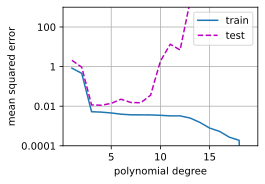

In [6]:
degrees = list(range(1, 20))
weights = [fit_degree(x_train, y_train, d) for d in degrees]
train_err = [mse(w, x_train, y_train) for w in weights]
test_err = [mse(w, x_test, y_test) for w in weights]
d2l.plot(degrees, [train_err, test_err], xlabel='polynomial degree',
         ylabel='mean squared error', legend=['train', 'test'],
         yscale='log', ylim=(1e-4, 1e3))

Training error falls with every added degree, as it must, and at degree 19
it lies far below the noise level, usually at zero up to rounding. Test error falls steeply until degree 3, is lowest at
degree 3 or a little above it, and then climbs by orders of magnitude. The
curve shows both failures at once: to the left of degree 3 the model is too
rigid to represent the cubic, and to the right its extra flexibility goes into
fitting the noise. Comparing the two errors tells us which failure we face.
Underfitting shows as a training error that stays high: the model cannot fit
even the data it was trained on. Overfitting shows as a test error far above
a low training error. A large gap is not a defect in itself, though; what we
care about is a low test error, and the best deep models often fit their
training data far better than held-out data.

### Bias and Variance

From degree 3 on, every model class contains the true cubic. Why, then, does
test error rise again? The fitted polynomial depends on the particular noise
in the 20 training labels. If we repeated the experiment with the same inputs
and fresh noise, we would get a different fit, and the more flexible the
model, the more the fits would differ. To make this precise, fix a test input
$x$ with label $y = f^*(x) + \epsilon$, and let $\hat{f}$ be the model fitted
to a random draw of the training noise. Taking the expectation over both the
training noise and the test noise $\epsilon$, the expected squared error
splits into three parts:

$$
\mathbb{E}\left[\big(y - \hat{f}(x)\big)^2\right] = \underbrace{\big(f^*(x) - \mathbb{E}[\hat{f}(x)]\big)^2}_{\textrm{bias}^2} + \underbrace{\textrm{Var}\big(\hat{f}(x)\big)}_{\textrm{variance}} + \sigma^2.
$$

The first term, the squared *bias*, is the squared distance between the
average fit and the truth: a systematic error that remains however often we
repeat the experiment. This bias, an error of the fitted function, is
unrelated to the bias $b$ of a linear model. The second, the *variance*,
measures how much the fit changes from one draw of the training noise to the
next. The third is the noise in the test label. To see why the error splits
this way, name the three parts of the prediction error: the test noise
$\epsilon$, the bias $\textrm{bias}(x) = f^*(x) - \mathbb{E}[\hat{f}(x)]$, and the
fluctuation $v = \mathbb{E}[\hat{f}(x)] - \hat{f}(x)$ of the fit around its average.
Then $y - \hat{f}(x) = \epsilon + \textrm{bias}(x) + v$, and

$$\mathbb{E}\left[\big(\epsilon + \textrm{bias}(x) + v\big)^2\right] = \mathbb{E}[\epsilon^2] + \textrm{bias}(x)^2 + \mathbb{E}[v^2] = \sigma^2 + \textrm{bias}(x)^2 + \textrm{Var}\big(\hat{f}(x)\big),$$

because every cross term has an expectation of zero: $\textrm{bias}(x)$ is a
constant, $\epsilon$ and $v$ have mean zero, and $\epsilon$ is independent
of $v$, which depends only on the training noise. The mathematics appendix
derives the decomposition for general estimators (that section).
The expectation here holds the training inputs fixed and redraws only the
noise. Averaging the risk of the fitted model over random training sets,
inputs included, adds the variation that comes from the choice of inputs, so
on average the variance is somewhat larger.

We can compute both terms in our experiment. The least-squares weights
$\hat{\mathbf{w}} = (\mathbf{X}^\top \mathbf{X})^{-1} \mathbf{X}^\top \mathbf{y}$
are a linear function of the labels, and the noise has mean zero. The average
of the fits over many draws of the noise is therefore the fit to the noiseless
labels $f^*(x^{(i)})$, and its error against $f^*$ on the test inputs is the
squared bias. For the variance, we refit on 200 fresh draws of the training
noise and measure how much the predictions at each test input spread. Both
terms are averaged over the test inputs.

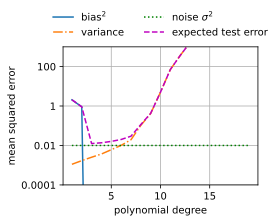

In [7]:
noise = rng.normal(0, sigma, (len(x_train), 200))   # 200 draws of the noise
bias2, var = [], []
for d in degrees:
    w_avg = fit_degree(x_train, target(x_train), d)               # average fit
    W = fit_degree(x_train, target(x_train)[:, None] + noise, d)  # fit per draw
    bias2.append(mse(w_avg, x_test, target(x_test)))
    var.append((features(x_test, d) @ W).var(axis=1).mean())
d2l.plot(degrees, [bias2, var, [sigma**2] * len(degrees),
                   np.add(bias2, var) + sigma**2],
         xlabel='polynomial degree', ylabel='mean squared error',
         fmts=('-', 'C1-.', 'g:', 'm--'), yscale='log', ylim=(1e-4, 1e3))
d2l.plt.legend(['bias$^2$', 'variance', r'noise $\sigma^2$',
                'expected test error'], ncol=2, frameon=False,
               loc='lower center', bbox_to_anchor=(0.5, 1));  # above the plot

The squared bias is large for degrees 1 and 2 and drops to zero, below the
bottom of the plot, at degree 3, where the model class first contains the
cubic. The variance grows with every added degree. At low degrees it is
roughly $\sigma^2 (d+1)/n$, the noise variance times the number of weights
per training example, and small compared with the noise; exercise
4 shows that this holds exactly on average
over the training inputs. At high degrees the variance exceeds the noise by
orders of magnitude. Their sum with $\sigma^2$, the expected test error, is
smallest at degree 3. Underfitting is error from bias, and overfitting is
error from variance.

The same trade-off appears in many model families, not only for
polynomials, as the figure sketches. Training error falls steadily. Test error falls while the bias
shrinks and rises once the variance dominates, so it is smallest at an
intermediate complexity, and it never drops below the noise level.

![Training and test error against model complexity. To the left of the best complexity the model underfits and both errors are high; to the right it overfits, its training error falls below the noise level, and the generalization gap widens.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-gen-capacity-error.svg)

### Model Complexity

The degree of a polynomial measures complexity by counting parameters. What
makes a class of models complex in general is its ability to fit many
different labelings of the same inputs, which we call its *capacity*.
Consider a class so flexible that for any $n$ inputs it can fit any labels
perfectly, even labels assigned at random. Polynomials of degree 19 on our 20
distinct inputs are such a class. A perfect fit to the training data
then tells us nothing, because the class would have fit any other labels just
as well [@vapnik1994measuring]. The philosopher Karl Popper made the
same point about scientific theories: a theory must rule out some possible
observations, and a theory that can explain any outcome gains no support from
the outcome it explains [@popper2005logic]. Conversely, if a class cannot
fit arbitrary labels and the sample is large compared with its capacity, a low
training error is evidence that the model has found a real pattern. Learning
theory turns this into bounds on the generalization gap, which the
mathematics appendix develops (that section).

Counting parameters is not the only way to measure capacity. The size of
the parameters matters too: the polynomial of degree 19 fit the training
points only by using weights of a million or more. A polynomial whose weights must stay small cannot swing so wildly
between data points, whatever its degree. Limiting the size of the weights is
the idea behind weight decay, the subject of the next section.

For deep neural networks, counting parameters fails even more clearly. Large
networks can fit randomly assigned labels on standard image datasets, yet
trained on the real labels they generalize well
[@zhang2021understanding]. Their training error alone therefore says
little about how well they generalize, and we rely on held-out data to
measure it. that section returns to this puzzle once
we have built such networks.

### Dataset Size

Complexity is relative to the amount of data. A polynomial of degree 19 has
as many weights as our 20 training examples, so it can memorize them. With
1,000 examples it cannot, and the noise in individual labels averages out. We
check this by fitting degrees 1, 3, and 19 to fresh training sets of
increasing size and evaluating each fit on the same test set.

In [8]:
for n in (20, 50, 100, 1000):
    x, y = make_data(rng, n, sigma)          # a fresh training set of size n
    errs = [mse(fit_degree(x, y, d), x_test, y_test) for d in (1, 3, 19)]
    print(f'n = {n:4d}: test error of degrees 1, 3, 19:',
          ', '.join(f'{e:.2g}' for e in errs))

n =   20: test error of degrees 1, 3, 19: 1.9, 0.012, 1.2e+10
n =   50: test error of degrees 1, 3, 19: 1.9, 0.01, 0.046
n =  100: test error of degrees 1, 3, 19: 1.9, 0.011, 0.032
n = 1000: test error of degrees 1, 3, 19: 1.9, 0.01, 0.01


More data helps the overfitting model enormously. With 100 examples the test
error of the polynomial of degree 19 has fallen by orders of magnitude, and
with 1,000 it matches that of the cubic. The straight line hardly improves:
with 1,000 examples its test error is still about 1.5 to 2. More data reduces
the variance, but not the bias. As a rule, the complexity of a model should
grow with the amount of data, not ahead of it.

## Model Selection

In the experiment we picked degree 3 by looking at the test error. That was a
demonstration, not a method. In practice we choose among many candidate
models, which may differ in architecture, in features, in the training
objective, or in hyperparameters (settings chosen before training rather than
learned) such as the learning rate and the number of epochs. Choosing among
candidates is called *model selection*, and we must do it without the test
set.

### Validation Sets

Why not select on the test set? Because the test error of the selected model
is then no longer an unbiased estimate of its generalization error. If we try
19 degrees and keep the one with the smallest test error, we keep the model
whose test error came out lowest partly by luck, and its reported error is
biased downward: we have overfit the test set. The bias grows with the number
of choices made this way, and it can be severe even for models whose
complexity is tightly controlled [@ong2005learning]. Nor can we select on
the training data, because the training error always favors the most flexible
candidate. In our sweep it would pick degree 19.

The standard remedy is to split the data three ways. The *training set* fits
the parameters of each candidate. The *validation set* estimates the
generalization error of each candidate, and we keep the best. The test set is
used once, at the end, to estimate the error of the chosen model. In practice
test sets are often reused across many rounds of experiments and many papers,
which invites the same bias. In this book, the held-out data we
report results on also serves to compare models, so unless stated otherwise,
the accuracies we report are validation accuracies rather than test
accuracies.

### Cross-Validation

When data is scarce, holding out a validation set of useful size leaves too
little for training: with our 20 examples, a validation set of 5 would take a
quarter of the data. *$K$-fold cross-validation* uses every example for both
purposes. It splits the training data into $K$ non-overlapping parts, called
*folds*. Each candidate model is trained $K$ times, each time on $K - 1$
folds, and evaluated on the remaining fold, as in the figure. The
average of the $K$ validation errors estimates the candidate's generalization
error. Once a candidate is chosen, we train it again on all the training data.

![In $K$-fold cross-validation, each of the $K$ folds serves once as the validation set (orange) while the model trains on the remaining folds (blue); the final estimate averages the $K$ validation scores.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-mlp-kfold.svg)

The folds must be random subsets of the data. Our 20 training examples were
drawn in random order, but real datasets often arrive sorted, by time, by
label, or by the value of a feature, and folds cut from consecutive examples
would then each cover only part of the inputs. `kfold_splits` therefore
divides a random permutation of the indices into $K$ folds with
`np.array_split`. The estimate also depends on which examples happen to
share a fold, noticeably so with folds of four examples. We reduce this
dependence by drawing several random splits, ten by default, and averaging
the validation errors over all of their folds, which is called *repeated*
cross-validation. Inside `cv_error`, `np.delete` removes the fold `f` from
the training data.

In [9]:
def kfold_splits(rng, n, K=5, repeats=10):
    """Random partitions of the indices 0, ..., n-1 into K folds."""
    return [np.array_split(rng.permutation(n), K) for _ in range(repeats)]

def cv_error(x, y, d, splits):
    """Validation error of the degree-d fit, averaged over all folds."""
    return np.mean([mse(fit_degree(np.delete(x, f), np.delete(y, f), d),
                        x[f], y[f]) for folds in splits for f in folds])

We now select the degree using only the 20 training examples. Every degree
is evaluated on the same splits, so that differences between degrees do not
come from differences between splits. We also print the degree with the
smallest test error, for comparison only; the selection never sees it.

In [10]:
splits = kfold_splits(rng, len(x_train))  # the same folds for every degree
cv_err = [cv_error(x_train, y_train, d, splits) for d in degrees]
print('cross-validation picks degree:', degrees[np.argmin(cv_err)])
print('lowest test error at degree:  ', degrees[np.argmin(test_err)])

cross-validation picks degree: 3
lowest test error at degree:   4


How closely does the cross-validation error follow the test error across
all degrees?

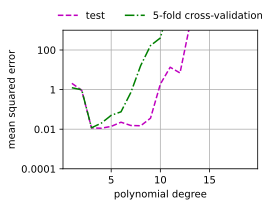

In [11]:
d2l.plot(degrees, [test_err, cv_err], xlabel='polynomial degree',
         ylabel='mean squared error', fmts=('m--', 'g-.'), yscale='log',
         ylim=(1e-4, 1e3))
d2l.plt.legend(['test', '5-fold cross-validation'], ncol=2, frameon=False,
               loc='lower center', bbox_to_anchor=(0.5, 1));  # above the plot

Cross-validation finds the bottom of the test error curve without touching
the test set. In about four runs out of five it picks degree 3, and
otherwise a degree between 4 and 7, whose test error is usually within 20%
of that of degree 3; exercise 6
measures how often each choice occurs and what a wrong choice costs. Near
the bottom the two curves agree to within a small factor, and the
cross-validation estimate is the noisier of the two, because it rests on 20
validation examples instead of 1,000. At high degrees it usually rises
earlier than the test error, and far higher. Each fold's model is fit to 16
points instead of 20, so at a given degree it has more weights per training
point: degree 15 already passes through all 16 points, as degree 19 does
through all 20. Some validation points also lie beyond the range of the 16
fitted points, near the ends of $[-1, 1]$, where a polynomial of high
degree swings far from the data.

How should we choose $K$? Each fold's model trains on only a fraction
$(K-1)/K$ of the data. If the error falls as the amount of training data
grows, as it usually does, each fold's model is somewhat worse than the model
we finally train on all the data, and the cross-validation estimate is
pessimistic. Taking $K = n$, called *leave-one-out* cross-validation, all but
removes this bias, but it requires $n$ fits per candidate. Its $n$ training
sets are also nearly identical, so the fold errors are strongly correlated and
their average tends to have a high variance. The usual compromise,
$K = 5$ or $K = 10$, keeps the bias moderate at the cost of 5 to 10 fits
[@Kohavi.1995]. Exercises 7
and 8 work out the bias of
the $K$-fold estimate, and a shortcut that makes leave-one-out as cheap as a
single fit for least squares.

We can now measure how well a model generalizes, recognize underfitting and
overfitting, and choose a model's flexibility with validation data. The
polynomial degree is a coarse control, though. Going from degree 3 to 4 adds
a whole new feature, and with many input variables the number of polynomial
features grows so fast that each step in degree is a large jump in capacity.
The experiment also suggested a finer control: the fit of degree 19 failed by
using enormous weights. The next section turns this observation into weight
decay, which penalizes large weights and adjusts capacity continuously.

## Summary

A model is useful only if it predicts well on new data from the distribution
of its training data, and its training error alone cannot tell us whether it
does. Under the IID assumption, the error on held-out data estimates the
generalization error, with a standard error that shrinks like $1/\sqrt{n'}$ in
the number $n'$ of held-out examples. A model that is too rigid underfits: its
training error is high, because of bias. A model that is too flexible for its
data overfits: its training error is low and its test error high, because of
variance. More data reduces the variance and lets us afford more flexible
models, while validation sets and $K$-fold cross-validation choose the
flexibility without touching the test set.

## Exercises

1. **When IID fails.** Give three examples in which dependent observations
   make treating a dataset as IID inadvisable. For each, state whether a
   random train/validation split overestimates or underestimates the
   generalization error, and describe a split that avoids the problem.

1. **Two kinds of zero error.** Under which circumstances can the training
   error be driven to zero? Under which circumstances can the
   generalization error be zero? Compare the two sets of conditions, and
   explain the role of the noise term $\sigma^2$ in the decomposition of
   the expected test error, the equation.

1. **Exact polynomial regression.** Show that when the $n$ training inputs
   $x^{(1)}, \ldots, x^{(n)}$ are distinct, a polynomial of degree $n-1$
   fits the $n$ labels exactly, and explain where distinctness is used.
   What does least squares return when two inputs coincide but their
   labels differ?

1. **Optimism of the training error.** ● Consider least squares with a
   fixed $n \times p$ design matrix $\mathbf{X}$ of full column rank and
   labels $\mathbf{y} = \mathbf{X}\mathbf{w}^* + \boldsymbol{\epsilon}$,
   whose noise terms are independent with mean zero and variance
   $\sigma^2$. The fitted predictions are
   $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ with
   $\mathbf{H} = \mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top$.
    1. Show that the expected training error is
       $\mathbb{E}[\|\mathbf{y} - \hat{\mathbf{y}}\|^2]/n = \sigma^2 (n - p)/n$.
       Hint: $\mathbf{y} - \hat{\mathbf{y}} = (\mathbf{I} - \mathbf{H})\boldsymbol{\epsilon}$,
       and the trace of $\mathbf{I} - \mathbf{H}$ is $n - p$.
    1. Draw fresh labels $\mathbf{y}' = \mathbf{X}\mathbf{w}^* + \boldsymbol{\epsilon}'$
       at the same inputs. Show that the expected error of
       $\hat{\mathbf{y}}$ on them is $\sigma^2 (n + p)/n$, so that the
       training error underestimates it by $2\sigma^2 p/n$. Show that
       $\sigma^2 p/n$ is the variance of the predictions, averaged over
       the $n$ inputs.
    1. Evaluate both expressions for the cubic fit of
       that section ($n = 20$, $p = 4$,
       $\sigma = 0.1$) and compare them with the training and test errors
       of degree 3 over several runs of the experiment. Explain the
       differences: how much does the training error of a single run
       spread around its expectation, and why does the formula of (b),
       which holds at the training inputs, not apply exactly to the test
       inputs?

1. [code] **Data size and model complexity.** Regenerate the polynomial data
   of that section and report every test error
   as the median over 20 runs, because a single draw fluctuates by
   about as much as the differences measured here.
    1. Your manager asks whether collecting more data would improve a
       model that performs poorly, before paying for any. Draw 100
       training examples, fit degrees 1, 3, and 10 on the first 20, 40,
       60, 80, and 100 of them, and plot the test error of each degree
       against the training-set size. Explain how the slope of each curve
       at 100 examples supports or undermines a request for more data.
    1. Sweep the degree from 1 to 29 with 10, 40, and 100 training
       examples. For each size, report the first degree above 3 at which
       the test error exceeds twice its value at degree 3. Relate the trend
       to the rule that the complexity of a model should grow with the
       amount of data, not ahead of it.

1. [code] **Reliability of cross-validation.** Repeat the selection of
   that section for 100 runs, each
   with its own 20 training examples. For each run, record the degree
   chosen by repeated 5-fold cross-validation, by 5-fold cross-validation
   with a single split, by leave-one-out cross-validation ($K = 20$, for
   which one split is all there is), and by the test error. How often does
   each method choose
   degree 3? When cross-validation chooses a different degree, by what
   factor does the test error of its choice exceed the test error of
   degree 3? Explain why a wrong choice is usually cheap here, and describe
   when it would be expensive.

1. **$K$-fold cross-validation.**
    1. Suppose that a model trained on $m$ examples has expected
       generalization error $R(m) = R_\infty + c/m$ with $c > 0$. Each
       fold's model trains on $(K-1)n/K$ examples. Compute the bias of the
       $K$-fold estimate relative to $R(n)$, the error of the model trained
       on all $n$ examples. Express the bias as a fraction of
       $R(n) - R_\infty$ and evaluate this fraction for $K = 2$, $5$, $10$,
       and $n$.
    1. After selecting a hyperparameter by cross-validation, the final
       model is retrained on all $n$ examples. Explain why a hyperparameter
       whose best value depends on the training-set size complicates this
       step, and give an example.

1. **Leave-one-out shortcut.** ● Leave-one-out cross-validation requires
   $n$ model fits for a general learner. Consider least squares with the
   design matrix $\mathbf{X}$, whose rows are $\mathbf{x}^{(i)\top}$. Let
   $\mathbf{A} = \mathbf{X}^\top\mathbf{X}$ and assume that it remains
   invertible when any one row of $\mathbf{X}$ is removed. Let
   $\hat{y}^{(i)}$ be the prediction at $\mathbf{x}^{(i)}$ of the fit on
   all $n$ examples, let $\hat{y}^{(-i)}$ be the prediction at
   $\mathbf{x}^{(i)}$ of the fit that omits example $i$, and let
   $h_i = \mathbf{x}^{(i)\top}\mathbf{A}^{-1}\mathbf{x}^{(i)}$. Use the
   Sherman--Morrison identity
   $$(\mathbf{A} - \mathbf{u}\mathbf{u}^\top)^{-1} = \mathbf{A}^{-1} + \frac{\mathbf{A}^{-1}\mathbf{u}\mathbf{u}^\top\mathbf{A}^{-1}}{1 - \mathbf{u}^\top\mathbf{A}^{-1}\mathbf{u}}$$
   with $\mathbf{u} = \mathbf{x}^{(i)}$ to show that
   $$y^{(i)} - \hat{y}^{(-i)} = \frac{y^{(i)} - \hat{y}^{(i)}}{1 - h_i}.$$
   State what leave-one-out cross-validation then costs for least
   squares compared with a single fit.

[Discussions](https://d2l.discourse.group/t/17978)